<a href="https://colab.research.google.com/github/quinnfraser03/vail-snow-lodging/blob/main/vail_snow_lodging.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Vail Resorts relies on overnight guests, and lodging is a key revenue driver. This project measures how much snowfall affects lodging revenue in the Town of Vail.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
# Base link to the data folder in our GitHub repo
base = "https://raw.githubusercontent.com/quinnfraser03/vail-snow-lodging/main/data/"

#Upload the two CSV files of data we are using for the project
lodging = pd.read_csv(base + "vail_lodging_monthly.csv")
snow = pd.read_csv(base + "vail_mountain_snotel_842_daily.csv")

print(lodging.shape, snow.shape)

(189, 5) (6240, 7)


The two files are Vail's lodging data and snow data. The lodging data comes from the Town of Vail's Finance Department, where every month the town publishes a report on lodging tax revenue for that month. The snow data is simply taken from the USDA's SNOTEL network of automated weather stations in the mountains. We used station 842 in this situation.

In [2]:
# Check column types and summary stats for each dataset
lodging.info()
snow.info()
snow.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 189 entries, 0 to 188
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   month              189 non-null    object 
 1   lodging_sales_tax  189 non-null    int64  
 2   tax_rate           189 non-null    float64
 3   source_report      189 non-null    object 
 4   source_url         189 non-null    object 
dtypes: float64(1), int64(1), object(3)
memory usage: 7.5+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6240 entries, 0 to 6239
Data columns (total 7 columns):
 #   Column                                               Non-Null Count  Dtype  
---  ------                                               --------------  -----  
 0   Date                                                 6240 non-null   object 
 1   Snow Water Equivalent (in) Start of Day Values       6240 non-null   float64
 2   Snow Depth (in) Start of Day Values                  6239 n

,Snow Water Equivalent (in) Start of Day Values,Snow Depth (in) Start of Day Values,Precipitation Accumulation (in) Start of Day Values,Air Temperature Average (degF),Air Temperature Maximum (degF),Air Temperature Minimum (degF)
count,6240.000000,6239.000000,6240.000000,6237.000000,6237.000000,6236.000000
mean,5.482228,17.930598,15.670256,36.386708,45.705034,28.325866
std,6.861818,20.597499,9.718999,16.526135,17.498927,15.774197
min,0.000000,0.000000,0.000000,-14.800000,-3.300000,-23.300000
25%,0.000000,0.000000,7.200000,23.200000,31.600000,16.000000
50%,1.900000,8.000000,16.000000,35.800000,45.700000,27.700000
75%,10.200000,36.000000,22.500000,51.400000,61.300000,43.000000
max,32.100000,84.000000,42.100000,67.800000,80.800000,59.700000


In [3]:
# Count missing values in each snow column
snow.isna().sum()

,0
Date,0
Snow Water Equivalent (in) Start of Day Values,0
Snow Depth (in) Start of Day Values,1
Precipitation Accumulation (in) Start of Day Values,0
Air Temperature Average (degF),3
Air Temperature Maximum (degF),3
Air Temperature Minimum (degF),4


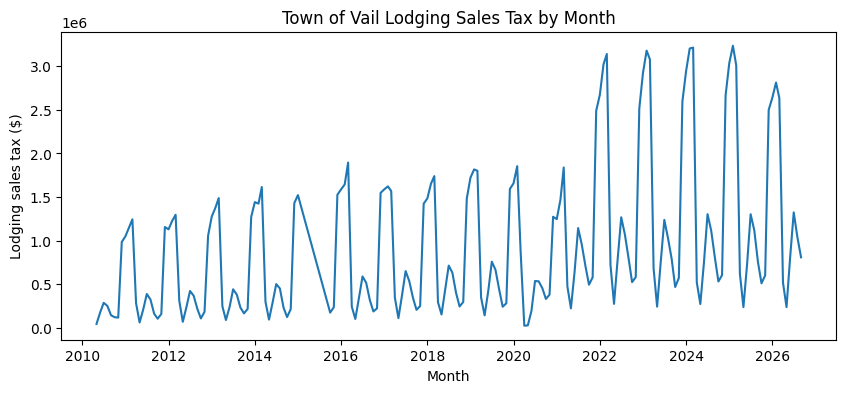

In [4]:
plt.figure(figsize=(10, 4))
plt.plot(pd.to_datetime(lodging["month"]), lodging["lodging_sales_tax"])
plt.title("Town of Vail Lodging Sales Tax by Month")
plt.xlabel("Month")
plt.ylabel("Lodging sales tax ($)")
plt.show()

This grpah above demonstrates the sales tax that the town of vail brings in per month, over a 16 year span.

In [5]:
# Rename the long column names so they're easier to work with
snow.columns = ["date", "swe", "snow_depth", "precip_accum",
                "avg_temp", "max_temp", "min_temp"]

# Turn the date text into real dates
snow["date"] = pd.to_datetime(snow["date"])
snow.head()

,date,swe,snow_depth,precip_accum,avg_temp,max_temp,min_temp
0,2009-10-01,0.0,0.0,0.0,19.9,27.0,14.9
1,2009-10-02,0.0,0.0,0.0,29.3,40.6,17.4
2,2009-10-03,0.0,0.0,0.1,38.1,49.6,28.0
3,2009-10-04,0.0,0.0,0.1,38.3,47.5,28.4
4,2009-10-05,0.0,0.0,0.1,26.2,35.6,17.4


In the cell above we simplified the column names, so that they are easier to work with. We also turned the text into actual dates for the file.

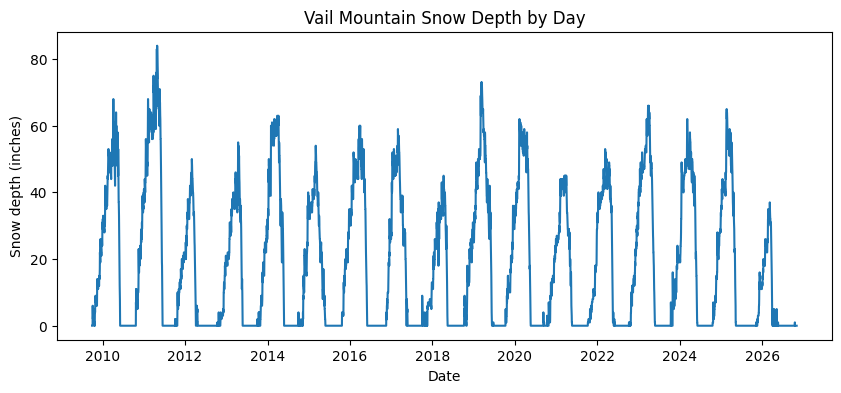

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(snow["date"], snow["snow_depth"])
plt.title("Vail Mountain Snow Depth by Day")
plt.xlabel("Date")
plt.ylabel("Snow depth (inches)")
plt.show()

This is a graph that demonstrates the snow depth by day, over a 16 year period of time.

In [7]:
# Fill each missing day with the day before (weather barely changes overnight)
snow = snow.ffill()
snow.isna().sum().sum()

np.int64(0)

We are begining to clean the data, here for each missing day of snow depth, we filled it with the data of the day before. We did this becasue the weather barely changes overnight.

In [8]:
# New snow = today's depth minus yesterday's (negative means melting, so set to 0)
snow["new_snow"] = snow["snow_depth"].diff().clip(lower=0)

# Big storm day = 6+ inches of new snow
snow["big_storm"] = (snow["new_snow"] >= 6).astype(int)

The code above made 2 new cells. Since out snowfall device only measures the snow on the ground, this added column uses an algorithm to meausre how much new snow there is. We also ade a new categorical column that measures if a strom was big or not (6 inches or more of new snow).

In [9]:
# Add a month column, then summarize each month's snow
snow["month"] = snow["date"].dt.to_period("M")

snow_monthly = snow.groupby("month").agg(
    avg_snow_depth=("snow_depth", "mean"),
    peak_swe=("swe", "max"),
    new_snow=("new_snow", "sum"),
    big_storm_days=("big_storm", "sum"),
    avg_temp=("avg_temp", "mean"),
).reset_index()

snow_monthly.shape

(205, 6)

This line of code, simplifies and condenses the daily data into monthly data for snowfall, so we can comapre it with the monthly lodging data.

In [10]:
# Guests book ahead, so last month's snowfall may matter too
snow_monthly["last_month_snow"] = snow_monthly["new_snow"].shift(1)
snow_monthly.tail()

,month,avg_snow_depth,peak_swe,new_snow,big_storm_days,avg_temp,last_month_snow
200,2026-06,0.000000,0.0,0.0,0,55.796667,9.0
201,2026-07,0.000000,0.1,0.0,0,61.193548,0.0
202,2026-08,0.000000,0.1,0.0,0,59.183871,0.0
203,2026-09,0.000000,0.0,0.0,0,50.826667,0.0
204,2026-10,0.032258,0.2,1.0,0,42.338710,0.0


This cell added a column for last months snowfall, that was we can analyse the affect previous snowfall has on lodging.

In [11]:
# Lodging revenue = tax collected / tax rate (4% before 2022, 4.5% after)
lodging["lodging_revenue"] = lodging["lodging_sales_tax"] / lodging["tax_rate"]

# Drop citation columns (not needed for modeling)
lodging = lodging.drop(columns=["source_report", "source_url"])

# Make month the same type as the snow data's month so they can merge
lodging["month"] = pd.PeriodIndex(lodging["month"], freq="M")
lodging.head()

,month,lodging_sales_tax,tax_rate,lodging_revenue
0,2010-05,42999,0.04,1074975.0
1,2010-06,175523,0.04,4388075.0
2,2010-07,285820,0.04,7145500.0
3,2010-08,250201,0.04,6255025.0
4,2010-09,143504,0.04,3587600.0


In this code, we are cleaning and preparing the data for modeling. First, we converted the tax revenue into lodging revenue by dividing the tax revenue by the tax rate. We also removed the citation columns showing which PDF the lodging data came from. Finally, we matched the monthly columns in the snow data and lodging data.

In [12]:
# Line up each month's lodging with that month's snow
df = lodging.merge(snow_monthly, on="month", how="left")
print(df.shape, df.isna().sum().sum())

(189, 10) 0


We merged the two data sets here, with a left join system.

In [13]:
# Month number and ski season flag (Nov-Apr)
df["month_num"] = df["month"].dt.month
df["ski_season"] = df["month_num"].isin([11, 12, 1, 2, 3, 4]).astype(int)

# Flag COVID months (Mar 2020 - May 2021)
df["covid"] = ((df["month"] >= "2020-03") & (df["month"] <= "2021-05")).astype(int)
df["covid"].sum()

np.int64(15)

Here we converted the months into a numeric value (January = 1). We also flagged the months that are during the ski season, as well as the months during the COVID pandemic, which could affect our data.

In [14]:
# How does each feature relate to lodging revenue?
df.corr(numeric_only=True)["lodging_revenue"].round(2)

,lodging_revenue
lodging_sales_tax,1.00
tax_rate,0.36
lodging_revenue,1.00
avg_snow_depth,0.53
peak_swe,0.29
new_snow,0.41
big_storm_days,0.19
avg_temp,-0.54
last_month_snow,0.34
month_num,-0.39


This shows the corelations between features and lodging revenue.

In [15]:
df.to_csv("vail_model_data.csv", index=False)

This finally saves the csv file under: vail_model_data.csv
